# Hype Meter: team-specific sentiment over the course of an NFL game

Pulls Bluesky posts from the window around a completed NFL game, tags posts by which team they mention, scores each post's "hype" with two sentiment models (a generic tweet-sentiment baseline vs. a sports-tuned model trained on hand-labeled posts from this game), and plots average hype over game time.

(Originally designed around Reddit game threads, but as of Reddit's Responsible Builder Policy (Nov 2025) self-serve API app creation is closed and the public API is shutting down entirely in Nov 2026 — so this pulls from Bluesky's open, unauthenticated `searchPosts` endpoint instead.)

In [1]:
import os
from datetime import datetime
from zoneinfo import ZoneInfo

import pandas as pd
import requests

from teams import tag_teams

SEARCH_URL = "https://api.bsky.app/xrpc/app.bsky.feed.searchPosts"

## 1. Define the game and search window

Prototyping against **LAR @ DEN, Sunday Night Football, 2026-09-27** — Denver
trailed 16-0 at halftime and won 30-26 on a go-ahead TD with 48 seconds left,
sealed by a game-ending endzone interception. Good test case for the same
reason as before: a long dominant stretch for one team followed by a dramatic,
sustained reversal, which should show up clearly in the time-binned average.
It's also a big enough national broadcast (and recent enough) to have solid
Bluesky volume — NFL-focused accounts and fan chatter have been a real,
growing presence there since early 2025.

`app.bsky.feed.searchPosts` takes `since`/`until` bounds, so we don't need to
locate a specific thread the way we did on Reddit — just bound the search to
the live window around kickoff.

In [2]:
TEAM_ABBRS = ["DEN", "LAR"]
TEAM_QUERIES = {"DEN": "Broncos", "LAR": "Rams"}
GAME_SLUG = "den_lar_2026-09-27"

kickoff_local = datetime(2026, 9, 27, 18, 20, tzinfo=ZoneInfo("America/Denver"))
kickoff_utc = kickoff_local.astimezone(ZoneInfo("UTC"))

SINCE = (kickoff_utc - pd.Timedelta(minutes=15)).strftime("%Y-%m-%dT%H:%M:%SZ")
UNTIL = (kickoff_utc + pd.Timedelta(hours=4, minutes=30)).strftime("%Y-%m-%dT%H:%M:%SZ")
print("kickoff (UTC):", kickoff_utc)
print("search window:", SINCE, "->", UNTIL)

kickoff (UTC): 2026-09-28 00:20:00+00:00
search window: 2026-09-28T00:05:00Z -> 2026-09-28T04:50:00Z


## 2. Search and cache posts

`searchPosts` allows one page (~100 results) per request without
authentication, but 403s on any `cursor` param — unauthenticated pagination
is blocked. Rather than requiring a Bluesky account, we slice the game window
into small time chunks and take the first page of each (no cursor needed) —
tested against this game's volume, a 10-minute chunk size only hits the
100-result cap in the single busiest window, so coverage is still near-complete.

In [3]:
def search_team_posts(query, since, until, chunk=pd.Timedelta(minutes=10)):
    posts = []
    t = since
    while t < until:
        t2 = min(t + chunk, until)
        params = {
            "q": query,
            "since": t.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "until": t2.strftime("%Y-%m-%dT%H:%M:%SZ"),
            "limit": 100,
            "sort": "latest",
        }
        resp = requests.get(SEARCH_URL, params=params, timeout=30)
        resp.raise_for_status()
        posts.extend(resp.json().get("posts", []))
        t = t2
    return posts


CACHE_PATH = f"data_cache/{GAME_SLUG}.parquet"

if os.path.exists(CACHE_PATH):
    posts_df = pd.read_parquet(CACHE_PATH)
else:
    since_ts, until_ts = pd.Timestamp(SINCE), pd.Timestamp(UNTIL)
    raw_posts = []
    for query in TEAM_QUERIES.values():
        raw_posts.extend(search_team_posts(query, since_ts, until_ts))

    by_uri = {
        p["uri"]: {"post_id": p["uri"], "body": p["record"]["text"], "created_at": p["record"]["createdAt"]}
        for p in raw_posts
    }
    posts_df = pd.DataFrame(by_uri.values())
    posts_df["created_at"] = pd.to_datetime(posts_df["created_at"], utc=True, format="mixed")
    posts_df["minutes_since_kickoff"] = (
        posts_df["created_at"] - pd.Timestamp(kickoff_utc)
    ).dt.total_seconds() / 60.0

    os.makedirs("data_cache", exist_ok=True)
    posts_df.to_parquet(CACHE_PATH, index=False)

print(len(posts_df), "unique posts")
posts_df.head()

1852 unique posts


,post_id,body,created_at,minutes_since_kickoff
0,at://did:plc:4ox6kqyumce5cer2gbn2mau7/app.bsky...,📺 [ #GaMeTiMe ]\nhttps://blossom.primal.net/81...,2026-09-28 00:15:00+00:00,-5.000000
1,at://did:plc:6aiuedv3bm5ybulgf2h5bod5/app.bsky...,"Bucky's stunt double, along with his security ...",2026-09-28 00:14:42.067000+00:00,-5.298883
2,at://did:plc:tr4cib3u27qz5ltiassjlr7b/app.bsky...,,2026-09-28 00:14:00+00:00,-6.000000
3,at://did:plc:jyxwd6sq74rce52uv7kvgbhi/app.bsky...,OK time to lock in,2026-09-28 00:13:46.653000+00:00,-6.222450
4,at://did:plc:zlx5b6fuezgzaq54rifok5un/app.bsky...,Nice,2026-09-28 00:13:29.556000+00:00,-6.507400


## 3. Tag posts by team

Only check the two teams actually in this game — checking all 32 at once would
pick up unrelated noise (e.g. "Bills" the common word). Posts that mention
both teams or neither are dropped from the per-team average: the point is a
team-specific hype score, not generic polarity, so an ambiguous post can't be
attributed to one side.

In [4]:
posts_df["teams_mentioned"] = posts_df["body"].apply(lambda t: tag_teams(t, TEAM_ABBRS))
posts_df["n_teams"] = posts_df["teams_mentioned"].apply(len)

tagged_df = posts_df[posts_df["n_teams"] == 1].copy()
tagged_df["team"] = tagged_df["teams_mentioned"].apply(lambda t: t[0])

print(posts_df["n_teams"].value_counts())
print(tagged_df["team"].value_counts())

n_teams
1    1468
2     306
0      78
Name: count, dtype: int64
team
DEN    777
LAR    691
Name: count, dtype: int64


## 4. Model 1 — generic baseline (tweet_eval)

TF-IDF + logistic regression trained on `tweet_eval`'s sentiment subset: real
tweets labeled negative/neutral/positive, free and no auth required. Tweet-style
text is a much closer match to game-thread comments than something like movie
reviews, so this is a fair baseline before we try a sports-specific model.

In [5]:
from datasets import load_dataset
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.pipeline import Pipeline

tweet_eval = load_dataset("cardiffnlp/tweet_eval", "sentiment")
# label ids: 0=negative, 1=neutral, 2=positive
X_train, y_train = tweet_eval["train"]["text"], tweet_eval["train"]["label"]
X_test, y_test = tweet_eval["test"]["text"], tweet_eval["test"]["label"]

model_generic = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=30_000, ngram_range=(1, 2), min_df=2)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model_generic.fit(X_train, y_train)

print(classification_report(y_test, model_generic.predict(X_test), target_names=["negative", "neutral", "positive"]))

              precision    recall  f1-score   support

    negative       0.56      0.66      0.61      3972
     neutral       0.65      0.55      0.60      5937
    positive       0.55      0.59      0.57      2375

    accuracy                           0.59     12284
   macro avg       0.59      0.60      0.59     12284
weighted avg       0.60      0.59      0.59     12284



## 5. Hand-label a sample of this game's posts

Run this from a terminal (not in the notebook — it's an interactive input loop):

```
source .venv/bin/activate
python label_comments.py --n 400
```

Samples across every game in `games.py` (stratified per game, so the labeled
set stays diverse). Asks for `p`/`u`/`n`/`o`/`s` — `o` is for posts the team
keyword-tagger caught but aren't actually about football (off-topic false
positives); those get recorded and excluded from both resampling and
training, same as a real label, just dropped before modeling. `s` is a true
skip — not recorded, so it can resurface later if you're unsure rather than
sure it's off-topic. Appends to `labeled_data/sports_labels.csv` after every
single label — so `Ctrl+C` any time and rerunning resumes where you left off.

## 6. Model 2 — sports-tuned (hand-labeled)

Same TF-IDF + logistic regression pipeline, but trained on the labels from
step 5 instead of generic tweets.

In [6]:
from sklearn.model_selection import train_test_split

label_to_id = {"negative": 0, "neutral": 1, "positive": 2}

sports_labels = pd.read_csv("labeled_data/sports_labels.csv")
n_off_topic = (sports_labels["label"] == "off_topic").sum()
print(f"{n_off_topic}/{len(sports_labels)} labeled off-topic (dropped before training)")
sports_labels = sports_labels[sports_labels["label"] != "off_topic"].copy()
sports_labels["label_id"] = sports_labels["label"].map(label_to_id)
print(sports_labels["label"].value_counts())

sX_train, sX_test, sy_train, sy_test = train_test_split(
    sports_labels["body"], sports_labels["label_id"], test_size=0.2, random_state=0, stratify=sports_labels["label_id"]
)

model_sports = Pipeline([
    ("tfidf", TfidfVectorizer(max_features=10_000, ngram_range=(1, 2), min_df=1)),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
])
model_sports.fit(sX_train, sy_train)

print(classification_report(sy_test, model_sports.predict(sX_test), target_names=["negative", "neutral", "positive"]))

27/502 labeled off-topic (dropped before training)
label
negative    173
neutral     155
positive    147
Name: count, dtype: int64
              precision    recall  f1-score   support

    negative       0.62      0.71      0.67        35
     neutral       0.44      0.48      0.46        31
    positive       0.52      0.38      0.44        29

    accuracy                           0.54        95
   macro avg       0.53      0.53      0.52        95
weighted avg       0.53      0.54      0.53        95



## 6b. Model 2 v2 — expanded with Claude-labeled data across 5 games

The 191-example model above is trained on hand labels alone. Separately,
`label_with_claude.py` used Claude Haiku 4.5 (via the Batches API, structured
outputs) to silver-label 4,736 more posts — the rest of this game plus four
more dramatic games (Raiders/Saints, Cardinals/Giants, Patriots/Bills,
Ravens/Falcons) — validated against a held-out slice of the hand labels first
(70.7% agreement, Cohen's κ = 0.548 — "moderate", mostly neutral-vs-negative
confusion on banter/trash-talk that two rounds of prompt tuning didn't move much).

Rather than trust that alone, we compare three training sets on the **same**
held-out human-labeled test split: human-only, human + Claude pooled
unweighted, and human + Claude with human examples upweighted to offset the
25:1 volume imbalance. Pooling unweighted won clearly — the moderate-agreement
labels carry real signal in aggregate, and down-weighting them to "trust humans
more" actually hurt, because it just left the big set underpowered. `model_sports`
is reassigned to that winner so the scoring/plotting cells below use it automatically.

In [7]:
import numpy as np
from sklearn.metrics import f1_score

claude_labels = pd.read_csv("labeled_data/claude_labels.csv")
n_overlap = claude_labels["post_id"].isin(sports_labels["post_id"]).sum()
claude_labels = claude_labels[~claude_labels["post_id"].isin(sports_labels["post_id"])].copy()
print(f"Dropped {n_overlap} Claude-labeled posts that now also have a human label (trust the human one)")
claude_labels["label_id"] = claude_labels["label"].map(label_to_id)

combined_X = pd.concat([sX_train, claude_labels["body"]])
combined_y = pd.concat([sy_train, claude_labels["label_id"]])


def make_sports_pipeline():
    return Pipeline([
        ("tfidf", TfidfVectorizer(max_features=20_000, ngram_range=(1, 2), min_df=2)),
        ("clf", LogisticRegression(max_iter=1000, class_weight="balanced")),
    ])


candidates = {}

candidates["human-only (n=%d)" % len(sX_train)] = make_sports_pipeline().fit(sX_train, sy_train)

candidates["combined unweighted (n=%d)" % len(combined_X)] = make_sports_pipeline().fit(combined_X, combined_y)

ratio = len(claude_labels) / len(sX_train)
weights = np.concatenate([np.full(len(sX_train), ratio), np.full(len(claude_labels), 1.0)])
m_weighted = make_sports_pipeline()
m_weighted.fit(combined_X, combined_y, clf__sample_weight=weights)
candidates["combined, human upweighted %.1fx" % ratio] = m_weighted

for name, model in candidates.items():
    preds = model.predict(sX_test)
    print(f"--- {name} ---")
    print(classification_report(sy_test, preds, target_names=["negative", "neutral", "positive"]))

best_name = max(candidates, key=lambda n: f1_score(sy_test, candidates[n].predict(sX_test), average="macro"))
print("Best on held-out human test set:", best_name)
model_sports = candidates[best_name]

Dropped 236 Claude-labeled posts that now also have a human label (trust the human one)


--- human-only (n=380) ---
              precision    recall  f1-score   support

    negative       0.62      0.60      0.61        35
     neutral       0.42      0.52      0.46        31
    positive       0.52      0.41      0.46        29

    accuracy                           0.52        95
   macro avg       0.52      0.51      0.51        95
weighted avg       0.52      0.52      0.52        95

--- combined unweighted (n=4880) ---
              precision    recall  f1-score   support

    negative       0.63      0.89      0.74        35
     neutral       0.64      0.45      0.53        31
    positive       0.67      0.55      0.60        29

    accuracy                           0.64        95
   macro avg       0.65      0.63      0.62        95
weighted avg       0.64      0.64      0.63        95

--- combined, human upweighted 11.8x ---
              precision    recall  f1-score   support

    negative       0.65      0.89      0.75        35
     neutral       0.60 

## 7. Score every tagged post

Hype is a continuous score, `P(positive) - P(negative)` from each model, in
`[-1, 1]`, rather than the discrete class — this is what makes the time-binned
average move smoothly instead of jumping between `{-1, 0, 1}`.

In [8]:
def hype_score(model, texts):
    proba = model.predict_proba(texts)
    classes = list(model.classes_)
    pos = proba[:, classes.index(2)]
    neg = proba[:, classes.index(0)]
    return pos - neg


tagged_df["hype_generic"] = hype_score(model_generic, tagged_df["body"])
tagged_df["hype_sports"] = hype_score(model_sports, tagged_df["body"])
tagged_df[["team", "minutes_since_kickoff", "hype_generic", "hype_sports"]].head()

,team,minutes_since_kickoff,hype_generic,hype_sports
1,DEN,-5.298883,0.005583,0.041282
8,DEN,-7.756683,0.233997,0.989469
9,DEN,-7.880250,0.519364,0.720332
10,DEN,-8.144983,0.302707,0.501241
11,DEN,-8.630683,-0.504055,0.064093


## 8. Bucket into time bins and smooth

At 2-minute bins, 32-51% of bins hold fewer than 3 posts — the chart was
mostly showing single-post noise, not an averaged signal. Two fixes, applied
together: widen bins to 10 minutes (median ~11-18 posts/bin instead of ~2-4,
<10% of bins left under 3 posts on either game), then run a 3-bin centered
rolling mean on top (a 30-minute effective smoothing window) to round off
what jaggedness remains without erasing real momentum shifts, which play out
over multiple minutes anyway, not within one.

In [9]:
BIN_MINUTES = 10
SMOOTH_WINDOW = 3


def aggregate_hype(df, bin_minutes=BIN_MINUTES, smooth_window=SMOOTH_WINDOW):
    d = df.copy()
    d["time_bin"] = (d["minutes_since_kickoff"] // bin_minutes) * bin_minutes

    binned = (
        d.groupby(["team", "time_bin"])[["hype_generic", "hype_sports"]]
        .mean()
        .reset_index()
        .sort_values(["team", "time_bin"])
    )
    for col in ["hype_generic", "hype_sports"]:
        binned[col] = binned.groupby("team")[col].transform(
            lambda s: s.rolling(smooth_window, center=True, min_periods=1).mean()
        )
    return binned


agg = aggregate_hype(tagged_df)
agg.head()

,team,time_bin,hype_generic,hype_sports
0,DEN,-20.0,0.041854,0.319840
1,DEN,-10.0,-0.007587,0.293472
2,DEN,0.0,-0.067204,0.150304
3,DEN,10.0,-0.153688,-0.056452
4,DEN,20.0,-0.126108,-0.203158


## 9. Plot hype over the course of the game

Two panels sharing one team→color mapping, so the same color always means the
same team: the generic baseline on top, the sports-tuned model on the bottom,
to see how much the fan-language-aware model's curve diverges from the
generic one — particularly around Denver's second-half comeback.

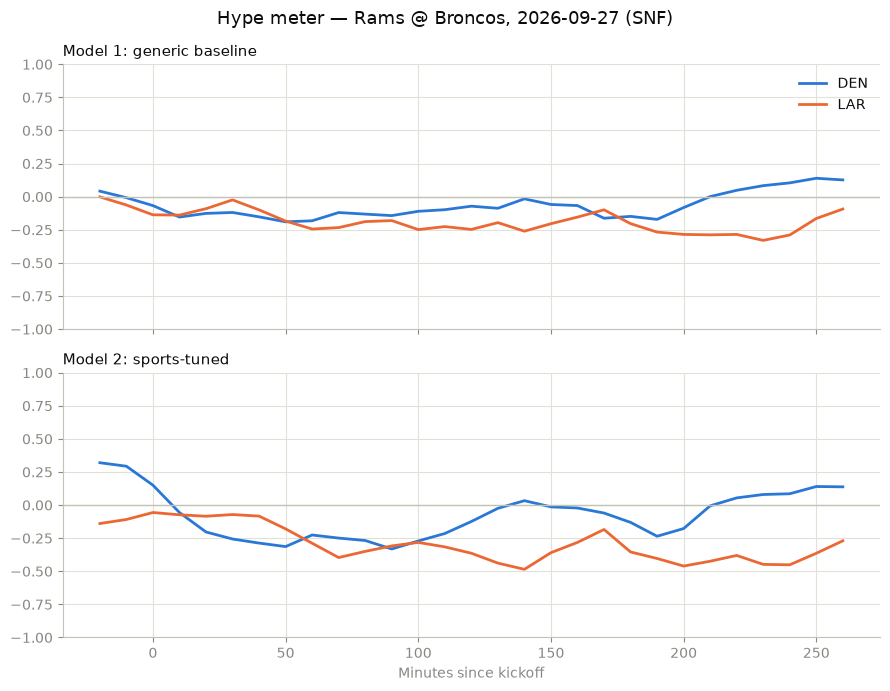

In [10]:
import matplotlib.pyplot as plt

TEAM_COLOR = {"DEN": "#2a78d6", "LAR": "#eb6834"}
INK = "#0b0b0b"
MUTED = "#898781"
GRID = "#e1e0d9"
BASELINE = "#c3c2b7"

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax, (col, title) in zip(axes, [("hype_generic", "Model 1: generic baseline"), ("hype_sports", "Model 2: sports-tuned")]):
    for team in TEAM_ABBRS:
        sub = agg[agg["team"] == team]
        ax.plot(sub["time_bin"], sub[col], color=TEAM_COLOR[team], linewidth=2, label=team)
    ax.axhline(0, color=BASELINE, linewidth=1)
    ax.set_ylim(-1, 1)
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(BASELINE)
    ax.tick_params(colors=MUTED)

axes[0].legend(frameon=False, labelcolor=INK)
axes[-1].set_xlabel("Minutes since kickoff", color=MUTED)
fig.suptitle("Hype meter — Rams @ Broncos, 2026-09-27 (SNF)", color=INK, fontsize=13)
fig.tight_layout()
plt.show()

## 9b. Line up the big plays

NFL play-by-play logs record game clock (e.g. "Q4, 0:47"), not wall-clock
time, so there's no direct way to place a play on a "minutes since kickoff"
axis. Instead: post *volume* (not sentiment) spikes in real time when
something big happens — fans react immediately — so we use spikes in our own
data as the timing signal, and the known scoring sequence to label what each
one is. Verified sequence for this game: Denver scored 16 unanswered in Q3 to
tie it 16-16 (one clean swing); then a chaotic final stretch — a Rams FG, a
Hufanga 66-yard pick-six for Denver's first lead (4:49 left), a Rams
48-yard TD to retake it, Bo Nix's go-ahead goal-line keeper (47 sec left),
and Hufanga's second interception, in the end zone, as time expired to seal
it — all within real minutes of each other, which is marked as one span
rather than claiming false precision about which post-rate spike belongs to
which individual play.

In [11]:
volume = tagged_df.groupby((tagged_df["minutes_since_kickoff"] // 5) * 5).size()
volume.sort_values(ascending=False).head(10)

minutes_since_kickoff
200.0    101
145.0     92
175.0     69
180.0     69
205.0     67
220.0     65
215.0     64
195.0     60
210.0     51
225.0     43
dtype: int64

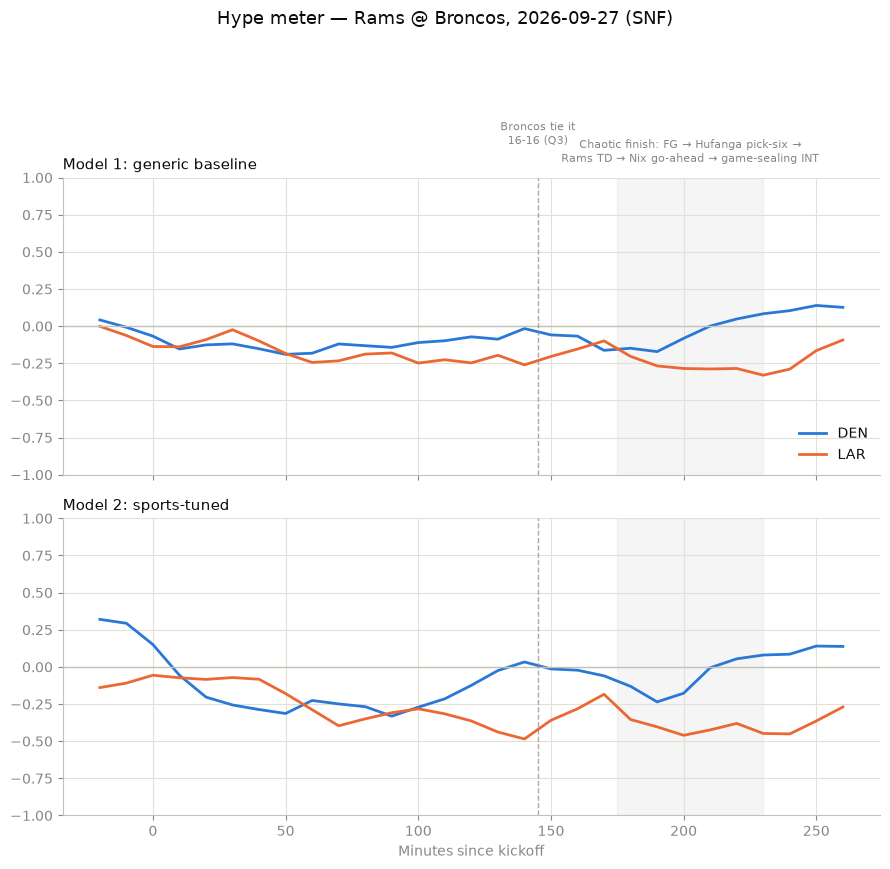

In [12]:
BIG_PLAYS = [
    {"type": "line", "x": 145, "label": "Broncos tie it\n16-16 (Q3)", "y": 1.20},
    {
        "type": "span",
        "x0": 175,
        "x1": 230,
        "label": "Chaotic finish: FG → Hufanga pick-six →\nRams TD → Nix go-ahead → game-sealing INT",
        "y": 1.08,
    },
]

fig, axes = plt.subplots(2, 1, figsize=(9, 8), sharex=True)

for ax, (col, title) in zip(axes, [("hype_generic", "Model 1: generic baseline"), ("hype_sports", "Model 2: sports-tuned")]):
    for team in TEAM_ABBRS:
        sub = agg[agg["team"] == team]
        ax.plot(sub["time_bin"], sub[col], color=TEAM_COLOR[team], linewidth=2, label=team)
    ax.axhline(0, color=BASELINE, linewidth=1)

    for play in BIG_PLAYS:
        if play["type"] == "line":
            ax.axvline(play["x"], color=MUTED, linewidth=1, linestyle="--", alpha=0.7)
        else:
            ax.axvspan(play["x0"], play["x1"], color=MUTED, alpha=0.08)

    ax.set_ylim(-1, 1)
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(BASELINE)
    ax.tick_params(colors=MUTED)

# Labels once, on the top panel only, staggered in height so they don't collide
for play in BIG_PLAYS:
    x = play["x"] if play["type"] == "line" else (play["x0"] + play["x1"]) / 2
    axes[0].annotate(
        play["label"], xy=(x, 1.0), xytext=(x, play["y"]), ha="center", va="bottom",
        fontsize=8, color=MUTED, annotation_clip=False,
    )

axes[0].legend(frameon=False, labelcolor=INK, loc="lower right")
axes[-1].set_xlabel("Minutes since kickoff", color=MUTED)
fig.suptitle("Hype meter — Rams @ Broncos, 2026-09-27 (SNF)", color=INK, fontsize=13, y=1.08)
fig.tight_layout()
plt.show()

## 10. Out-of-sample test: a brand-new game

Everything above — both models — was trained on posts from the 5 games in
`games.py`. To see how this generalizes, score a game neither model has ever
seen: **NYG @ WAS, 2026-10-11** — the Commanders led a comeback into overtime,
then infamously ran out the clock on themselves without spiking the ball,
settling for a 27-27 tie. A bizarre, high-emotion ending is a good stress test
for a sentiment model trained on more conventional wins/losses.

This game is intentionally **not** added to `games.py` — it stays out of any
future retraining so it's always a clean holdout.

In [13]:
from fetch_bluesky import fetch_game

holdout_game = {
    "slug": "nyg_was_2026-10-11",
    "teams": ["NYG", "WAS"],
    "queries": {"NYG": "Giants", "WAS": "Commanders"},
    "kickoff": datetime(2026, 10, 11, 13, 0, tzinfo=ZoneInfo("America/New_York")),
}

holdout_df = fetch_game(holdout_game)
print(len(holdout_df), "tagged posts")
print(holdout_df["team"].value_counts())

889 tagged posts
team
NYG    495
WAS    394
Name: count, dtype: int64


In [14]:
holdout_df["hype_generic"] = hype_score(model_generic, holdout_df["body"])
holdout_df["hype_sports"] = hype_score(model_sports, holdout_df["body"])

holdout_agg = aggregate_hype(holdout_df)
holdout_agg.head()

,team,time_bin,hype_generic,hype_sports
0,NYG,-20.0,-0.122482,-0.063806
1,NYG,-10.0,-0.085551,0.029686
2,NYG,0.0,-0.141313,-0.005065
3,NYG,10.0,-0.090708,0.064372
4,NYG,20.0,-0.081098,0.003608


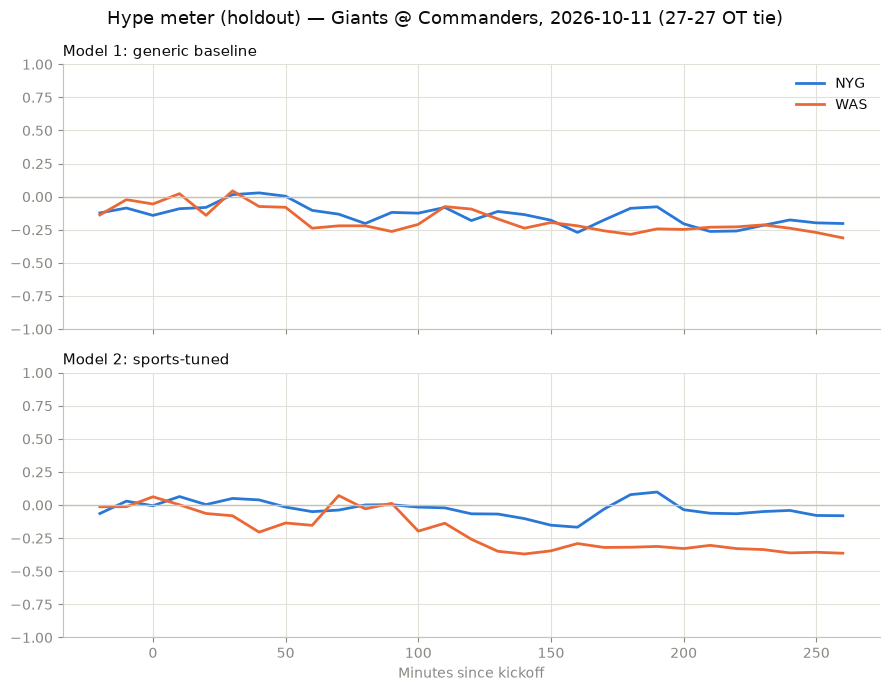

In [15]:
holdout_colors = {"NYG": "#2a78d6", "WAS": "#eb6834"}

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

for ax, (col, title) in zip(axes, [("hype_generic", "Model 1: generic baseline"), ("hype_sports", "Model 2: sports-tuned")]):
    for team in ["NYG", "WAS"]:
        sub = holdout_agg[holdout_agg["team"] == team]
        ax.plot(sub["time_bin"], sub[col], color=holdout_colors[team], linewidth=2, label=team)
    ax.axhline(0, color=BASELINE, linewidth=1)
    ax.set_ylim(-1, 1)
    ax.set_title(title, color=INK, fontsize=11, loc="left")
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(BASELINE)
    ax.tick_params(colors=MUTED)

axes[0].legend(frameon=False, labelcolor=INK)
axes[-1].set_xlabel("Minutes since kickoff", color=MUTED)
fig.suptitle("Hype meter (holdout) — Giants @ Commanders, 2026-10-11 (27-27 OT tie)", color=INK, fontsize=13)
fig.tight_layout()
plt.show()